In [1]:
import pandas, numpy, scipy

In [2]:
import sklearn, sklearn.preprocessing, sklearn.decomposition

In [3]:
import matplotlib, matplotlib.pyplot
matplotlib.rcParams.update({'font.size':20, 
                            'font.family':'sans-serif', 
                            'xtick.labelsize':16, 
                            'ytick.labelsize':16, 
                            'figure.figsize':(16*(2/3), 9*(2/3)), 
                            'axes.labelsize':20
                           })

# 0. user-defined variables

# 1. read expression

In [4]:
input_file = '/Users/adrian/research/bmcbf/067_urmia/results/01_primary/profiles/DESeq2_TPM_values.tsv'
prima = pandas.read_csv(input_file, sep='\t', index_col=0)
prima = prima.add_prefix("primary_")
print(prima.shape)
prima

(39546, 9)


,primary_PNT1,primary_PNT2,primary_PNT3,primary_PT251,primary_PT252,primary_PT253,primary_PT501,primary_PT502,primary_PT503
ENSG00000000003.15,60.010164,56.864285,67.530799,42.741514,53.950983,38.825483,28.545982,31.894017,27.811313
ENSG00000000005.6,0.000000,0.000000,0.000000,0.000000,0.079146,0.000000,0.000000,0.000000,0.000000
ENSG00000000419.14,74.269017,70.981144,80.958673,68.736836,71.528195,76.100282,70.167383,77.002498,74.407704
ENSG00000000457.14,8.006860,8.168558,8.666231,9.626468,9.814037,6.308987,7.687010,7.633767,8.561684
ENSG00000000460.17,2.532638,2.156166,4.032114,2.843206,3.701280,2.306823,2.328512,2.455071,2.896012
...,...,...,...,...,...,...,...,...,...
ENSG00000291297.1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
ENSG00000291298.1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
ENSG00000291299.1,3.037490,2.813491,2.286681,2.380306,2.019163,2.365784,2.512866,2.189668,2.195346
ENSG00000291300.1,0.488906,0.294105,1.026266,0.787008,0.364076,0.687859,0.967987,0.305009,0.698456


In [5]:
input_file = '/Users/adrian/research/bmcbf/067_urmia/results/02_bioprint/DESeq2_TPM_values.tsv'
df = pandas.read_csv(input_file, sep='\t', index_col=0)
df = df.add_prefix("bioprint_")
print(df.shape)

expression = pandas.concat([prima, df], axis=1)
print(expression.shape)
expression

(39546, 9)
(39546, 18)


,primary_PNT1,primary_PNT2,primary_PNT3,primary_PT251,primary_PT252,primary_PT253,primary_PT501,primary_PT502,primary_PT503,bioprint_NT1,bioprint_NT2,bioprint_NT3,bioprint_T251,bioprint_T252,bioprint_T253,bioprint_T501,bioprint_T502,bioprint_T503
ENSG00000000003.15,60.010164,56.864285,67.530799,42.741514,53.950983,38.825483,28.545982,31.894017,27.811313,60.564951,35.605355,52.717329,25.256284,38.907441,28.970683,28.965279,26.041029,16.469214
ENSG00000000005.6,0.000000,0.000000,0.000000,0.000000,0.079146,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
ENSG00000000419.14,74.269017,70.981144,80.958673,68.736836,71.528195,76.100282,70.167383,77.002498,74.407704,74.850831,67.812030,76.124126,53.783296,69.351428,63.312700,41.899294,37.065104,26.995653
ENSG00000000457.14,8.006860,8.168558,8.666231,9.626468,9.814037,6.308987,7.687010,7.633767,8.561684,12.867233,8.396116,9.701365,6.890270,7.625112,5.927822,4.161594,3.046070,1.705487
ENSG00000000460.17,2.532638,2.156166,4.032114,2.843206,3.701280,2.306823,2.328512,2.455071,2.896012,7.033218,3.205917,3.965620,6.508230,3.062286,2.971540,2.614795,3.918652,0.720946
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ENSG00000291297.1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
ENSG00000291298.1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
ENSG00000291299.1,3.037490,2.813491,2.286681,2.380306,2.019163,2.365784,2.512866,2.189668,2.195346,8.540801,4.026774,5.836038,1.529988,2.379372,1.047746,2.975697,1.145590,0.618863
ENSG00000291300.1,0.488906,0.294105,1.026266,0.787008,0.364076,0.687859,0.967987,0.305009,0.698456,0.083306,0.138637,0.068762,0.072035,0.215792,0.057721,0.000000,0.024969,0.000000


# 3. filter and transform

In [7]:
substantial_expression = expression[expression.max(axis=1) >= 2]
high_expression = expression[expression.max(axis=1) >= 100]

print(substantial_expression.shape)
print(high_expression.shape)

(15371, 18)
(2020, 18)


In [8]:
transpose = substantial_expression.transpose()
pca_substantial_expression = numpy.log2(transpose + 1)

transpose = high_expression.transpose()
pca_high_expression = numpy.log2(transpose + 1)

# 4. visualize high expression

In [9]:
scaled_data = sklearn.preprocessing.StandardScaler().fit_transform(pca_high_expression)
model = sklearn.decomposition.PCA(n_components=2)
new = model.fit_transform(scaled_data)
explained = model.explained_variance_ratio_
print(explained)

[0.56305139 0.23065944]


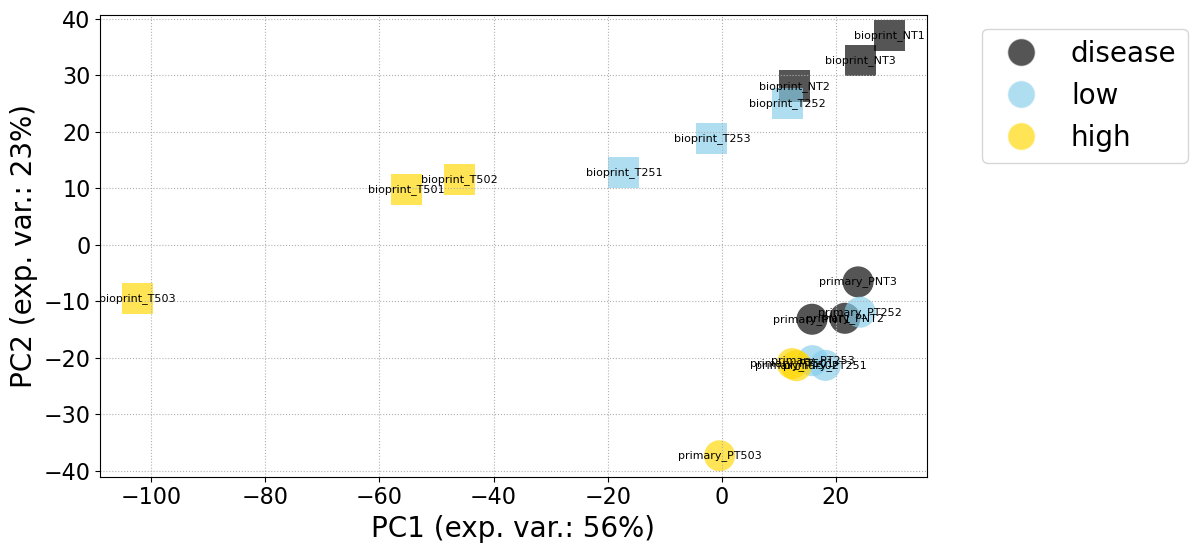

In [11]:
for i in range(len(new)):

    name = expression.columns[i]

    # colors
    if 'NT' in name:
        the_color = 'black'
    elif 'T25' in name:
        the_color = 'skyblue'
    elif 'T50' in name:
        the_color = 'gold'
    else:
        print(name)
        print('error')

    # markers
    if 'bioprint' in name:
        the_marker = 's'
    else:
        the_marker = 'o'
        
    matplotlib.pyplot.scatter(new[i,0], new[i,1], s=500, c=the_color, marker=the_marker, alpha=2/3, edgecolors='none')
    epsilon = 0
    matplotlib.pyplot.text(new[i,0]+epsilon, new[i,1]+epsilon, name, size=8, va='center', ha='center')

legend_elements = [
    matplotlib.lines.Line2D([0], [0], color='white', marker='o', markerfacecolor='black', markeredgecolor='white', markersize=20, alpha=2/3),
    matplotlib.lines.Line2D([0], [0], color='white', marker='o', markerfacecolor='skyblue', markeredgecolor='white', markersize=20, alpha=2/3),
    matplotlib.lines.Line2D([0], [0], color='white', marker='o', markerfacecolor='gold', markeredgecolor='white', markersize=20, alpha=2/3)
]

matplotlib.pyplot.legend(legend_elements, ['disease', 'low', 'high'], ncol=1, loc='upper left', bbox_to_anchor=(1.05, 1))

matplotlib.pyplot.xlabel('PC1 (exp. var.: {}%)'.format(int(explained[0]*100)))
matplotlib.pyplot.ylabel('PC2 (exp. var.: {}%)'.format(int(explained[1]*100)))
matplotlib.pyplot.grid(ls=':')

matplotlib.pyplot.show()
#matplotlib.pyplot.savefig('pca.svg')